# Detección de zonas candidatas a resiembra mediante segmentación semántica

**Materia:** Redes Neuronales  
**Salida:** máscara semántica y porcentajes de césped, suelo expuesto y otra vegetación.

Este notebook es autónomo y está preparado para Google Colab. Lee **CSIRO-Biomass-Seg** únicamente desde un ZIP ya alojado en Google Drive, valida y extrae el archivo de forma segura, comprueba los pares imagen–máscara y verifica la codificación semántica documentada por el dataset.

Las regiones clasificadas como suelo se describen únicamente como **sectores candidatos a revisión**. No se realizan prescripciones agronómicas ni cálculos de superficie.

## Uso rápido

1. En Colab, elegir un entorno con GPU.
2. Revisar la celda **Configuración central** y ajustar las dos rutas de Drive si fuera necesario.
3. Ejecutar en orden. La primera corrida es de humo (`FAST_MODE=True`) y la corrida completa acotada se habilita con `RUN_FULL=True`.
4. El remapeo está documentado y fijado en el notebook: `Green→césped`, `Ground→suelo expuesto`, `Clover→otra vegetación`; Background, Dead Matter y Covering se ignoran con 255.

Los resultados generados durante la ejecución se guardan en `/content/Proyecto_Cesped/outputs/`.


In [1]:
# 1. Instalación de dependencias compatibles con Google Colab.
# Se conserva PyTorch/CUDA y OpenCV provistos por Colab.

%pip install -q --upgrade \
    "segmentation-models-pytorch==0.5.0" \
    "albumentations==1.4.24" \
    "scikit-learn>=1.6,<1.8" \
    "seaborn==0.13.2" \
    "tabulate==0.9.0"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.9/274.9 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 117.7 MB/s eta 0:00:00


In [2]:
# 2. Importaciones, versiones efectivas y configuración central.
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import sys
import time
import warnings
import zipfile
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from pathlib import Path, PurePosixPath
from typing import Any, Iterable, Optional

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import segmentation_models_pytorch as smp
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore", category=UserWarning)
plt.style.use("seaborn-v0_8-whitegrid")

@dataclass(frozen=True)
class Config:
    seed: int = 42
    patch_size: int = 512
    batch_size: int = 2
    num_workers: int = 2
    fast_mode: bool = True
    run_smoke: bool = True
    run_full: bool = True
    max_public_images: int = 300
    smoke_per_split: int = 6
    zip_drive_path: str = "/content/drive/MyDrive/Proyecto_Cesped/csiro-biomass-seg.zip"
    local_zip_drive_path: str = "/content/drive/MyDrive/Proyecto_Cesped/local.zip"
    work_dir: str = "/content/Proyecto_Cesped"
    persist_to_drive: bool = False
    drive_output_dir: str = "/content/drive/MyDrive/Proyecto_Cesped/resultados"

CFG = Config()
FAST_MODE = CFG.fast_mode
RUN_SMOKE = CFG.run_smoke
RUN_FULL = CFG.run_full
MAX_PUBLIC_IMAGES = CFG.max_public_images
ZIP_DRIVE_PATH = CFG.zip_drive_path
LOCAL_ZIP_DRIVE_PATH = CFG.local_zip_drive_path

# Codificación publicada en ReadMe.py de CSIRO-Biomass-Seg:
# 0 Background, 1 Clover, 2 Green, 3 Dead Matter, 4 Ground, 5 Covering.
# Las clases ambiguas para este objetivo se excluyen con 255.
CSIRO_RAW_TO_TARGET: dict[int, int] = {
    0: 255,  # Background
    1: 2,    # Clover -> otra vegetación
    2: 0,    # Green -> césped/vegetación verde principal
    3: 255,  # Dead Matter -> ambiguo para las tres clases
    4: 1,    # Ground -> suelo expuesto
    5: 255,  # Covering -> región no utilizable
}

ROOT = Path(CFG.work_dir)
DATA_DIR = ROOT / "data"
PUBLIC_DIR = DATA_DIR / "csiro_biomass_seg"
LOCAL_DIR = DATA_DIR / "local"
OUTPUT_DIR = ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
CKPT_DIR = OUTPUT_DIR / "checkpoints"
HISTORY_DIR = OUTPUT_DIR / "histories"
MANIFEST_DIR = OUTPUT_DIR / "manifests"
for folder in [DATA_DIR, OUTPUT_DIR, FIG_DIR, CKPT_DIR, HISTORY_DIR, MANIFEST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG.seed)

VERSIONS = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "torch": torch.__version__, "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda, "device": str(DEVICE),
    "segmentation_models_pytorch": smp.__version__,
    "albumentations": A.__version__, "opencv": cv2.__version__,
    "numpy": np.__version__, "pandas": pd.__version__,
    "seaborn": sns.__version__, "scikit_learn": sklearn.__version__,
}
(OUTPUT_DIR / "versions.json").write_text(json.dumps(VERSIONS, indent=2), encoding="utf-8")
(OUTPUT_DIR / "config.json").write_text(json.dumps(asdict(CFG), indent=2), encoding="utf-8")
print(json.dumps(VERSIONS, indent=2))
print(f"Dispositivo seleccionado: {DEVICE}")


/usr/local/lib/python3.13/dist-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.24). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


{
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "cuda_available": true,
  "cuda_runtime": "13.0",
  "device": "cuda",
  "segmentation_models_pytorch": "0.5.0",
  "albumentations": "1.4.24",
  "opencv": "4.14.0",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "seaborn": "0.13.2",
  "scikit_learn": "1.7.2"
}
Dispositivo seleccionado: cuda


## 1. Google Drive, validación y extracción segura

La extracción rechaza rutas absolutas, `..` y cualquier entrada que escape al destino. También prueba la integridad del ZIP y evita reextraer si ya existe un marcador válido. El ZIP público es obligatorio; el ZIP local es opcional.


In [3]:
# 3. Montaje de Google Drive.
try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError("Este notebook debe ejecutarse en Google Colab para montar Drive.") from exc

drive.mount("/content/drive")


Mounted at /content/drive


In [4]:
# 4. Validación y extracción segura e idempotente.
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
MASK_EXTS = IMAGE_EXTS | {".npy"}
MASK_HINTS = {
    "mask", "masks", "label", "labels", "annotation", "annotations",
    "semantic", "segmentation", "seg", "target", "targets", "class", "classes",
    "groundtruth", "ground_truth", "ground-truth", "truth", "gt",
}

def _safe_member_destination(base: Path, member_name: str) -> Path:
    pure = PurePosixPath(member_name.replace("\\", "/"))
    if pure.is_absolute() or ".." in pure.parts:
        raise ValueError(f"Entrada ZIP insegura: {member_name!r}")
    destination = (base / Path(*pure.parts)).resolve()
    base_resolved = base.resolve()
    if destination != base_resolved and base_resolved not in destination.parents:
        raise ValueError(f"Path traversal detectado: {member_name!r}")
    return destination

def zip_inventory(zip_path: Path) -> dict[str, Any]:
    if not zip_path.exists():
        raise FileNotFoundError(
            f"No se encontró el ZIP público en {zip_path}. "
            "Subilo a esa ruta de Google Drive o modificá ZIP_DRIVE_PATH en Config."
        )
    if not zipfile.is_zipfile(zip_path):
        raise ValueError(f"El archivo no es un ZIP válido: {zip_path}")
    with zipfile.ZipFile(zip_path) as zf:
        bad = zf.testzip()
        if bad is not None:
            raise ValueError(f"ZIP corrupto; primera entrada dañada: {bad}")
        files = [i for i in zf.infolist() if not i.is_dir()]
        for info in files:
            _safe_member_destination(Path("/tmp/zip-safety-check"), info.filename)
        images = [i for i in files if Path(i.filename).suffix.lower() in IMAGE_EXTS]
        likely_masks = [
            i for i in files
            if Path(i.filename).suffix.lower() in MASK_EXTS
            and any(h in i.filename.lower() for h in MASK_HINTS)
        ]
        docs = [i for i in files if Path(i.filename).suffix.lower() in {".txt", ".md", ".csv", ".json", ".pdf", ".py"}]
        if not images:
            raise ValueError("El ZIP no contiene imágenes reconocibles.")
        if not likely_masks:
            print(
                "ADVERTENCIA: no se reconocieron máscaras por el nombre de archivo/carpeta. "
                "Verificá que descargaste CSIRO-Biomass-Seg completo y que conserva la carpeta labels/. "
                "Se extraerá para mostrar la estructura, pero el entrenamiento se detendrá si no hay pares válidos."
            )
        return {
            "files": len(files), "images": len(images), "likely_masks": len(likely_masks),
            "docs": len(docs), "uncompressed_bytes": sum(i.file_size for i in files),
        }

def safe_extract_zip(zip_path: Path, destination: Path, required: bool) -> Optional[dict[str, Any]]:
    if not zip_path.exists():
        if required:
            return zip_inventory(zip_path)  # genera el mensaje claro
        print(f"ZIP local opcional no encontrado: {zip_path}. E4/E5 quedarán como no ejecutados.")
        return None
    inventory = zip_inventory(zip_path)
    marker = destination / ".extraction_complete.json"
    if marker.exists() and any(p for p in destination.rglob("*") if p.is_file() and p != marker):
        print(f"Contenido ya extraído; se reutiliza {destination}")
        return json.loads(marker.read_text(encoding="utf-8"))
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        for info in zf.infolist():
            target = _safe_member_destination(destination, info.filename)
            if info.is_dir():
                target.mkdir(parents=True, exist_ok=True)
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(info) as source, target.open("wb") as sink:
                shutil.copyfileobj(source, sink)
    marker.write_text(json.dumps(inventory, indent=2), encoding="utf-8")
    print(f"Extraídos {inventory['files']} archivos en {destination}")
    return inventory

public_inventory = safe_extract_zip(Path(ZIP_DRIVE_PATH), PUBLIC_DIR, required=True)
local_inventory = safe_extract_zip(Path(LOCAL_ZIP_DRIVE_PATH), LOCAL_DIR, required=False)
print("Resumen público:", public_inventory)
print("Resumen local:", local_inventory)


Extraídos 715 archivos en /content/Proyecto_Cesped/data/csiro_biomass_seg
ZIP local opcional no encontrado: /content/drive/MyDrive/Proyecto_Cesped/local.zip. E4/E5 quedarán como no ejecutados.
Resumen público: {'files': 715, 'images': 714, 'likely_masks': 357, 'docs': 1, 'uncompressed_bytes': 503434841}
Resumen local: None


In [5]:
# 5. Estructura real y documentación incluida antes de emparejar archivos.
def directory_summary(root: Path, max_depth: int = 3) -> pd.DataFrame:
    rows = []
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.name.startswith(".extraction_complete"):
            continue
        rel = p.relative_to(root)
        if len(rel.parts) <= max_depth:
            rows.append({"ruta": str(rel), "extension": p.suffix.lower(), "bytes": p.stat().st_size})
    return pd.DataFrame(rows)

structure_df = directory_summary(PUBLIC_DIR)
display(structure_df.head(100))
print(f"Archivos visibles en el resumen: {len(structure_df)}")
print(f"Tamaño total extraído: {sum(p.stat().st_size for p in PUBLIC_DIR.rglob('*') if p.is_file()) / 1e9:.3f} GB")

doc_paths = [p for p in PUBLIC_DIR.rglob("*") if p.suffix.lower() in {".txt", ".md", ".csv", ".json", ".py"}]
print("Documentación/metadata encontrada:")
for p in doc_paths[:30]:
    print(" -", p.relative_to(PUBLIC_DIR))

for p in doc_paths[:8]:
    if p.stat().st_size <= 250_000:
        print(f"\n--- {p.relative_to(PUBLIC_DIR)} ---")
        print(p.read_text(encoding="utf-8", errors="replace")[:3000])


,ruta,extension,bytes
0,ReadMe.py,.py,3298
1,images/ID1011485656.jpg,.jpg,1588644
2,images/ID1012260530.jpg,.jpg,1457681
3,images/ID1025234388.jpg,.jpg,1367167
4,images/ID1028611175.jpg,.jpg,1594302
...,...,...,...
95,images/ID1473228876.jpg,.jpg,1583639
96,images/ID1474775613.jpg,.jpg,1372967
97,images/ID147528735.jpg,.jpg,1280883
98,images/ID1476045099.jpg,.jpg,1469561


Archivos visibles en el resumen: 715
Tamaño total extraído: 0.503 GB
Documentación/metadata encontrada:
 - .extraction_complete.json
 - ReadMe.py

--- .extraction_complete.json ---
{
  "files": 715,
  "images": 714,
  "likely_masks": 357,
  "docs": 1,
  "uncompressed_bytes": 503434841
}

--- ReadMe.py ---
"""
Semantic Segmentation Visualization for CSIRO - Image2Biomass Prediction
----------------------------------------------------------------------
This script visualizes pixel-level annotations for the Kaggle CSIRO competition.
Dataset Link: https://www.kaggle.com/c/csiro-biomass

PURPOSE:
These pixel-level masks can be used for multi-task learning and enhancing
supervision during the training of biomass prediction models.

FILE ORGANIZATION:
/Dataset_Root/
├── images/           # Original RGB images (.jpg)
└── labels/           # Single-channel label masks (.png)

PIXEL VALUE MAPPING (LABEL SEMANTICS):
In the label .png files, each pixel value represents a specific class:
    0: Bac

## 2. Descubrimiento, inspección semántica y manifiestos

El código busca recursivamente y empareja por identificador normalizado. **No presupone rutas absolutas**, pero verifica la estructura esperada `images/` y `labels/`. La codificación se contrasta con `ReadMe.py` incluido en el ZIP.

Remapeo conservador para este objetivo:

- `Green` (2) → 0, césped/vegetación verde principal.
- `Ground` (4) → 1, suelo expuesto.
- `Clover` (1) → 2, otra vegetación.
- `Background`, `Dead Matter` y `Covering` → 255, ignorar.

`Green` es la fracción verde no trébol del conjunto de pasturas; se usa como aproximación de césped y esta limitación queda documentada.


In [5]:
# 6. Descubrimiento y emparejamiento conservador de imágenes/máscaras.
def normalized_stem(path: Path) -> str:
    s = path.stem.lower()
    suffixes = [
        "_semantic_mask", "_semantic", "_segmentation", "_annotation", "_annotations",
        "_label", "_labels", "_mask", "_target", "_targets", "_class", "_classes", "_seg", "_gt",
    ]
    for suffix in suffixes:
        if s.endswith(suffix):
            s = s[:-len(suffix)]
    return re.sub(r"[^a-z0-9]+", "", s)

def is_likely_mask(path: Path) -> bool:
    # Evitamos falsos positivos evaluando solo el nombre del archivo y la carpeta contenedora inmediata
    parent_name = path.parent.name.lower()
    name_low = path.name.lower()
    is_in_labels = parent_name == "labels"
    has_mask_hint = any(h in name_low for h in MASK_HINTS) or (parent_name in MASK_HINTS)
    return is_in_labels or has_mask_hint

def looks_like_discrete_mask(path: Path, max_colors: int = 64) -> bool:
    # Heurística sólo para descubrir candidatos; la semántica se confirma después.
    if path.suffix.lower() == ".npy":
        arr = np.load(path, mmap_mode="r")
        if arr.ndim not in (2, 3):
            return False
        sample = np.asarray(arr[::max(1, arr.shape[0] // 256), ::max(1, arr.shape[1] // 256)])
    else:
        with Image.open(path) as im:
            im.thumbnail((256, 256), Image.Resampling.NEAREST)
            sample = np.asarray(im)
    if sample.ndim == 2:
        return len(np.unique(sample)) <= max_colors
    if sample.ndim == 3 and sample.shape[2] in (3, 4):
        return len(np.unique(sample[:, :, :3].reshape(-1, 3), axis=0)) <= max_colors
    return False

def image_size(path: Path) -> tuple[int, int]:
    if path.suffix.lower() == ".npy":
        arr = np.load(path, mmap_mode="r")
        return int(arr.shape[1]), int(arr.shape[0])
    with Image.open(path) as im:
        return im.size

def infer_site(path: Path) -> str:
    patterns = re.compile(r"(site|farm|field|plot|location|camera)[-_ ]?[a-z0-9]+", re.I)
    for part in reversed(path.parts[:-1]):
        match = patterns.search(part)
        if match:
            return match.group(0).lower().replace(" ", "_")
    return "unknown"

def discover_pairs(root: Path) -> pd.DataFrame:
    candidates = [p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in MASK_EXTS]
    masks = [p for p in candidates if is_likely_mask(p)]
    if not masks:
        masks = [p for p in candidates if looks_like_discrete_mask(p)]
        print(f"Descubrimiento alternativo por contenido discreto: {len(masks)} candidatos a máscara.")
    images = [p for p in candidates if p.suffix.lower() in IMAGE_EXTS and p not in masks]
    image_index: dict[str, list[Path]] = defaultdict(list)
    for p in images:
        image_index[normalized_stem(p)].append(p)
    rows, unmatched, ambiguous = [], [], []
    for mask in masks:
        key = normalized_stem(mask)
        choices = image_index.get(key, [])
        if not choices:
            unmatched.append(mask)
            continue
        try:
            msize = image_size(mask)
            same_size = [p for p in choices if image_size(p) == msize]
            if same_size:
                choices = same_size
        except Exception:
            pass
        if len(choices) != 1:
            ambiguous.append((mask, choices))
            continue
        image = choices[0]
        source_id = hashlib.sha1(str(image.relative_to(root)).encode()).hexdigest()[:16]
        rows.append({
            "image_path": str(image), "mask_path": str(mask),
            "source_image_id": source_id, "site_id": infer_site(image),
            "domain": "public", "relative_image": str(image.relative_to(root)),
        })
    print(f"Imágenes candidatas: {len(images)} | máscaras candidatas: {len(masks)}")
    print(f"Pares únicos: {len(rows)} | máscaras sin par: {len(unmatched)} | ambiguas: {len(ambiguous)}")
    if unmatched[:10]:
        print("Primeras máscaras sin par:", [str(p.relative_to(root)) for p in unmatched[:10]])
    if ambiguous[:5]:
        print("Primeros emparejamientos ambiguos:", [(str(m.relative_to(root)), len(c)) for m, c in ambiguous[:5]])
    if not rows:
        raise RuntimeError(
            "No se encontraron pares imagen–máscara semántica inequívocos. "
            "No se usarán imágenes sin etiqueta ni CSV de biomasa como sustituto."
        )
    return pd.DataFrame(rows)

public_pairs = discover_pairs(PUBLIC_DIR)
display(public_pairs.head())

Imágenes candidatas: 357 | máscaras candidatas: 357
Pares únicos: 357 | máscaras sin par: 0 | ambiguas: 0


,image_path,mask_path,source_image_id,site_id,domain,relative_image
0,/content/Proyecto_Cesped/data/csiro_biomass_se...,/content/Proyecto_Cesped/data/csiro_biomass_se...,5439d4b9e40f924a,unknown,public,images/ID905397692.jpg
1,/content/Proyecto_Cesped/data/csiro_biomass_se...,/content/Proyecto_Cesped/data/csiro_biomass_se...,aacc4f8f9b7c203c,unknown,public,images/ID1509266870.jpg
2,/content/Proyecto_Cesped/data/csiro_biomass_se...,/content/Proyecto_Cesped/data/csiro_biomass_se...,18a4009cea674004,unknown,public,images/ID1859792585.jpg
3,/content/Proyecto_Cesped/data/csiro_biomass_se...,/content/Proyecto_Cesped/data/csiro_biomass_se...,b613271409e166d5,unknown,public,images/ID2131261930.jpg
4,/content/Proyecto_Cesped/data/csiro_biomass_se...,/content/Proyecto_Cesped/data/csiro_biomass_se...,002338c7304bdfed,unknown,public,images/ID1113329413.jpg


In [6]:
# 7. Inspección de valores, colores, dimensiones y posibles anotaciones de instancia.
def read_raw_mask(path: str | Path) -> np.ndarray:
    path = Path(path)
    if path.suffix.lower() == ".npy":
        arr = np.load(path)
    else:
        arr = np.array(Image.open(path))
    if arr.ndim == 3 and arr.shape[2] == 4:
        arr = arr[:, :, :3]
    return arr

def inspect_masks(df: pd.DataFrame, n: int = 12) -> pd.DataFrame:
    rows = []
    sample = df.sample(min(n, len(df)), random_state=CFG.seed)
    for path in sample["mask_path"]:
        arr = read_raw_mask(path)
        if arr.ndim == 2:
            vals, counts = np.unique(arr, return_counts=True)
            summary = dict(zip(vals[:30].tolist(), counts[:30].tolist()))
            n_unique = len(vals)
        elif arr.ndim == 3 and arr.shape[2] == 3:
            flat = arr.reshape(-1, 3)
            vals, counts = np.unique(flat, axis=0, return_counts=True)
            summary = {tuple(v.tolist()): int(c) for v, c in zip(vals[:30], counts[:30])}
            n_unique = len(vals)
        else:
            summary, n_unique = f"shape no compatible: {arr.shape}", -1
        rows.append({"mask_path": path, "shape": arr.shape, "dtype": str(arr.dtype), "n_unique": n_unique, "values_or_colors": summary})
    return pd.DataFrame(rows)

mask_inspection = inspect_masks(public_pairs)
pd.set_option("display.max_colwidth", 200)
display(mask_inspection)

if (mask_inspection["n_unique"] > 6).any():
    raise RuntimeError("Se observaron más de seis valores; esas máscaras no coinciden con CSIRO-Biomass-Seg.")
print("Inspección compatible con máscaras discretas CSIRO (valores esperados 0–5).")


,mask_path,shape,dtype,n_unique,values_or_colors
0,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID668475812.png,"(1000, 2000)",uint8,3,"{2: 1466969, 3: 363841, 4: 169190}"
1,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID158170916.png,"(1000, 2000)",uint8,5,"{1: 228792, 2: 1739858, 3: 11496, 4: 3838, 5: 16016}"
2,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID1011485656.png,"(1000, 2000)",uint8,6,"{0: 105, 1: 18728, 2: 1926023, 3: 34225, 4: 2349, 5: 18570}"
3,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID1693880739.png,"(1000, 2000)",uint8,4,"{2: 1948971, 3: 43329, 4: 755, 5: 6945}"
4,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID1119761112.png,"(1000, 2000)",uint8,4,"{2: 1416123, 3: 421715, 4: 146749, 5: 15413}"
5,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID1051144034.png,"(1000, 2000)",uint8,5,"{1: 1899366, 2: 16630, 3: 46412, 4: 19803, 5: 17789}"
6,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID294150104.png,"(1000, 2000)",uint8,4,"{1: 562321, 2: 1402851, 3: 14233, 5: 20595}"
7,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID2006686196.png,"(1000, 2000)",uint8,3,"{2: 839022, 3: 1146466, 5: 14512}"
8,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID2053315094.png,"(1000, 2000)",uint8,3,"{2: 1426889, 3: 563983, 5: 9128}"
9,/content/Proyecto_Cesped/data/csiro_biomass_seg/labels/ID983582017.png,"(1000, 2000)",uint8,4,"{2: 1937145, 3: 40519, 4: 10662, 5: 11674}"


Inspección compatible con máscaras discretas CSIRO (valores esperados 0–5).


In [7]:
# 8. Validación de la semántica documentada por CSIRO-Biomass-Seg y remapeo.
EXPECTED_SCHEMA_TEXT = {
    "0: Background", "1: Clover", "2: Green",
    "3: Dead Matter", "4: Ground", "5: Covering",
}

def validate_csiro_documentation(root: Path) -> None:
    readmes = [p for p in root.rglob("ReadMe.py") if p.is_file()]
    if len(readmes) != 1:
        raise RuntimeError("Se esperaba exactamente un ReadMe.py de CSIRO-Biomass-Seg.")
    text = readmes[0].read_text(encoding="utf-8", errors="replace")
    missing = sorted(token for token in EXPECTED_SCHEMA_TEXT if token not in text)
    if missing:
        raise RuntimeError(f"La documentación no confirma el esquema CSIRO esperado: {missing}")

def remap_public_mask(raw: np.ndarray) -> np.ndarray:
    if raw.ndim != 2:
        raise ValueError(f"La máscara CSIRO debe ser monocanal; shape observado: {raw.shape}")
    observed = {int(v) for v in np.unique(raw)}
    unknown = observed - set(CSIRO_RAW_TO_TARGET)
    if unknown:
        raise ValueError(f"Valores CSIRO no documentados: {sorted(unknown)}")
    out = np.full(raw.shape, 255, dtype=np.uint8)
    for raw_id, target_id in CSIRO_RAW_TO_TARGET.items():
        out[raw == raw_id] = target_id
    return out

validate_csiro_documentation(PUBLIC_DIR)
observed_global = set()
for path in public_pairs["mask_path"]:
    raw = read_raw_mask(path)
    observed_global |= {int(v) for v in np.unique(raw)}
    mapped = remap_public_mask(raw)
    assert set(np.unique(mapped)).issubset({0, 1, 2, 255})
missing_core = {1, 2, 4} - observed_global
if missing_core:
    raise RuntimeError(f"Faltan clases esenciales en todo el conjunto: {sorted(missing_core)}")
print("Esquema CSIRO verificado. Valores observados:", sorted(observed_global))
print("Remapeo aplicado:", CSIRO_RAW_TO_TARGET)


Esquema CSIRO verificado. Valores observados: [0, 1, 2, 3, 4, 5]
Remapeo aplicado: {0: 255, 1: 2, 2: 0, 3: 255, 4: 1, 5: 255}


In [8]:
# 9. Selección reproducible ANTES de dividir; duplicados y split 70/15/15 por grupos.
def sha256_file(path: str | Path, chunk: int = 1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while data := f.read(chunk):
            h.update(data)
    return h.hexdigest()

def select_reproducible_subset(df: pd.DataFrame, limit: int) -> pd.DataFrame:
    ranked = df.copy()
    ranked["selection_key"] = ranked["source_image_id"].map(
        lambda s: hashlib.sha256(f"{CFG.seed}:{s}".encode()).hexdigest()
    )
    return ranked.sort_values("selection_key").head(min(limit, len(ranked))).drop(columns="selection_key").reset_index(drop=True)

def assign_group_splits(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["image_sha256"] = out["image_path"].map(sha256_file)
    # Sitios conocidos se mantienen juntos; si no hay sitio, se agrupan duplicados exactos.
    out["split_group"] = np.where(
        out["site_id"].ne("unknown"), "site:" + out["site_id"], "hash:" + out["image_sha256"]
    )
    groups = out[["split_group"]].drop_duplicates().copy()
    if len(groups) < 3:
        raise RuntimeError("Se requieren al menos tres grupos independientes para train/validation/test.")
    rng = np.random.default_rng(CFG.seed)
    order = rng.permutation(len(groups))
    groups = groups.iloc[order].reset_index(drop=True)
    n = len(groups)
    n_test = max(1, round(0.15 * n))
    n_val = max(1, round(0.15 * n))
    if n_test + n_val >= n:
        n_test, n_val = 1, 1
    groups["split"] = "train"
    groups.loc[:n_test - 1, "split"] = "test"
    groups.loc[n_test:n_test + n_val - 1, "split"] = "validation"
    out = out.merge(groups, on="split_group", how="left")
    return out

def assert_no_leakage(df: pd.DataFrame) -> None:
    for column in ["source_image_id", "image_sha256"]:
        counts = df.groupby(column)["split"].nunique()
        assert counts.max() == 1, f"Leakage por {column}"
    known = df[df["site_id"].ne("unknown")]
    if len(known):
        assert known.groupby("site_id")["split"].nunique().max() == 1, "Leakage por site_id"
    assert set(df["split"]) == {"train", "validation", "test"}

public_manifest = assign_group_splits(select_reproducible_subset(public_pairs, MAX_PUBLIC_IMAGES))
assert_no_leakage(public_manifest)
public_manifest.to_csv(MANIFEST_DIR / "public_manifest.csv", index=False)
print("Los resultados corresponderán a este subconjunto público reproducible:")
display(public_manifest.groupby(["domain", "split"]).size().rename("imagenes").reset_index())
print("Duplicados exactos:", int(public_manifest.duplicated("image_sha256", keep=False).sum()))


Los resultados corresponderán a este subconjunto público reproducible:


,domain,split,imagenes
0,public,test,45
1,public,train,210
2,public,validation,45


Duplicados exactos: 0


In [9]:
# 10. Datos locales opcionales: estructura fija y validaciones por jardín.
def build_local_manifest(root: Path) -> Optional[pd.DataFrame]:
    metadata_candidates = list(root.rglob("metadata.csv"))
    if not metadata_candidates:
        print("E4/E5 no ejecutado: sin datos locales (metadata.csv ausente).")
        return None
    metadata_path = metadata_candidates[0]
    base = metadata_path.parent
    meta = pd.read_csv(metadata_path, dtype=str).fillna("")
    required = {"image_name", "mask_name", "garden_id", "split"}
    if not required.issubset(meta.columns):
        raise ValueError(f"metadata.csv debe contener {sorted(required)}")
    rows = []
    for _, r in meta.iterrows():
        image = base / "images" / r.image_name
        mask = base / "masks" / r.mask_name if r.mask_name else None
        if not image.exists():
            raise FileNotFoundError(image)
        if r["split"] != "demo" and (mask is None or not mask.exists()):
            raise FileNotFoundError(f"Falta máscara anotada para {image.name}")
        if mask is not None:
            raw = read_raw_mask(mask)
            if raw.ndim != 2 or not set(np.unique(raw)).issubset({0, 1, 2, 255}):
                raise ValueError(f"Máscara local inválida: {mask}")
            if image_size(image) != image_size(mask):
                raise ValueError(f"Desalineación de tamaño: {image} vs {mask}")
        source_id = hashlib.sha1(str(image.relative_to(base)).encode()).hexdigest()[:16]
        rows.append({
            "image_path": str(image), "mask_path": str(mask) if mask else "",
            "source_image_id": source_id, "site_id": r.garden_id,
            "split": r["split"], "domain": "local", "garden_id": r.garden_id,
            "image_sha256": sha256_file(image),
        })
    out = pd.DataFrame(rows)
    allowed_splits = {"train", "validation", "test", "demo"}
    if not set(out["split"]).issubset(allowed_splits):
        raise ValueError(f"Splits locales inválidos: {set(out['split']) - allowed_splits}")
    garden_leak = out[out["split"].ne("demo")].groupby("garden_id")["split"].nunique()
    assert garden_leak.max() == 1, "Cada garden_id anotado debe aparecer en una única partición"
    expected = {"train": 6, "validation": 2, "test": 4, "demo": 4}
    observed = out.groupby("split").size().to_dict()
    if any(observed.get(k, 0) != v for k, v in expected.items()):
        print("Advertencia: el conteo local difiere del objetivo 6/2/4 anotadas + 4 demo:", observed)
    out.to_csv(MANIFEST_DIR / "local_manifest.csv", index=False)
    display(out.groupby(["split", "garden_id"]).size().rename("imagenes").reset_index())
    return out

local_manifest = build_local_manifest(LOCAL_DIR) if local_inventory is not None else None


## 3. Lectura alineada, patches y EDA

La orientación EXIF de la imagen se aplica también a su máscara. Las máscaras siempre usan interpolación *nearest-neighbor*. El conjunto de entrenamiento recibe aumentos sincronizados; validación y test reciben una transformación determinista.


In [11]:
# 11. Lectura con orientación EXIF, transformaciones y Dataset.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

def apply_exif_orientation(im: Image.Image, orientation: int) -> Image.Image:
    operations = {
        2: Image.Transpose.FLIP_LEFT_RIGHT,
        3: Image.Transpose.ROTATE_180,
        4: Image.Transpose.FLIP_TOP_BOTTOM,
        5: Image.Transpose.TRANSPOSE,
        6: Image.Transpose.ROTATE_270,
        7: Image.Transpose.TRANSVERSE,
        8: Image.Transpose.ROTATE_90,
    }
    return im.transpose(operations[orientation]) if orientation in operations else im

def load_aligned_pair(image_path: str, mask_path: str, domain: str) -> tuple[np.ndarray, Optional[np.ndarray]]:
    with Image.open(image_path) as pil_image:
        orientation = int(pil_image.getexif().get(274, 1))
        image = apply_exif_orientation(pil_image.convert("RGB"), orientation)
        image_arr = np.array(image)
    if not mask_path:
        return image_arr, None
    raw = read_raw_mask(mask_path)
    if raw.ndim == 2:
        mask_pil = Image.fromarray(raw)
        raw = np.array(apply_exif_orientation(mask_pil, orientation))
    elif raw.ndim == 3:
        mask_pil = Image.fromarray(raw.astype(np.uint8))
        raw = np.array(apply_exif_orientation(mask_pil, orientation))
    mask = remap_public_mask(raw) if domain == "public" else raw.astype(np.uint8)
    if image_arr.shape[:2] != mask.shape[:2]:
        raise ValueError(f"Imagen/máscara desalineadas: {image_path} {image_arr.shape} vs {mask_path} {mask.shape}")
    if not set(np.unique(mask)).issubset({0, 1, 2, 255}):
        raise ValueError(f"Valores no permitidos en {mask_path}")
    return image_arr, mask

def train_transform(size: int = 512) -> A.Compose:
    return A.Compose([
        A.PadIfNeeded(size, size, border_mode=cv2.BORDER_REFLECT_101, value=0, mask_value=255),
        A.RandomResizedCrop(size, size, scale=(0.70, 1.0), ratio=(0.90, 1.10), interpolation=cv2.INTER_LINEAR),
        A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.25),
        A.ShiftScaleRotate(shift_limit=0.04, scale_limit=0.10, rotate_limit=15,
                           interpolation=cv2.INTER_LINEAR, border_mode=cv2.BORDER_REFLECT_101,
                           value=0, mask_value=255, p=0.65),
        A.Perspective(scale=(0.02, 0.05), interpolation=cv2.INTER_LINEAR,
                      pad_mode=cv2.BORDER_REFLECT_101, pad_val=0, mask_pad_val=255, p=0.20),
        A.RandomBrightnessContrast(brightness_limit=0.20, contrast_limit=0.20, p=0.50),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def eval_transform(size: int = 512) -> A.Compose:
    return A.Compose([
        A.PadIfNeeded(size, size, border_mode=cv2.BORDER_REFLECT_101, value=0, mask_value=255),
        A.CenterCrop(size, size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

class LawnPatchDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, training: bool):
        self.frame = frame.reset_index(drop=True)
        self.transform = train_transform(CFG.patch_size) if training else eval_transform(CFG.patch_size)
    def __len__(self) -> int:
        return len(self.frame)
    def __getitem__(self, idx: int) -> dict[str, Any]:
        row = self.frame.iloc[idx]
        image, mask = load_aligned_pair(row.image_path, row.mask_path, row.domain)
        transformed = self.transform(image=image, mask=mask)
        x = torch.from_numpy(transformed["image"].transpose(2, 0, 1)).float()
        y = torch.from_numpy(transformed["mask"]).long()
        return {"image": x, "mask": y, "id": row.source_image_id, "image_path": row.image_path}

def subset_for_mode(df: pd.DataFrame, fast: bool) -> pd.DataFrame:
    if not fast:
        return df.copy()
    return (df.groupby("split", group_keys=False)
              .apply(lambda x: x.sample(min(len(x), CFG.smoke_per_split), random_state=CFG.seed))
              .reset_index(drop=True))

def make_loaders(df: pd.DataFrame, batch_size: int) -> dict[str, DataLoader]:
    loaders = {}
    for split in ["train", "validation", "test"]:
        part = df[df["split"].eq(split)]
        ds = LawnPatchDataset(part, training=(split == "train"))
        loaders[split] = DataLoader(
            ds, batch_size=batch_size, shuffle=(split == "train"),
            num_workers=CFG.num_workers, pin_memory=AMP_ENABLED, drop_last=False,
        )
    return loaders


,domain,split,n
0,public,test,45
1,public,train,210
2,public,validation,45


width                                                      height  \
            count    mean  std     min     25%     50%     75%     max  count   
split                                                                           
test         45.0  2000.0  0.0  2000.0  2000.0  2000.0  2000.0  2000.0   45.0   
train       210.0  2000.0  0.0  2000.0  2000.0  2000.0  2000.0  2000.0  210.0   
validation   45.0  2000.0  0.0  2000.0  2000.0  2000.0  2000.0  2000.0   45.0   

                                                                 
              mean  std     min     25%     50%     75%     max  
split                                                            
test        1000.0  0.0  1000.0  1000.0  1000.0  1000.0  1000.0  
train       1000.0  0.0  1000.0  1000.0  1000.0  1000.0  1000.0  
validation  1000.0  0.0  1000.0  1000.0  1000.0  1000.0  1000.0

,clase,pixeles,proporcion
0,césped,387104023,0.645173
1,suelo expuesto,39388947,0.065648
2,otra vegetación,83424646,0.139041
3,ignore,90082384,0.150137


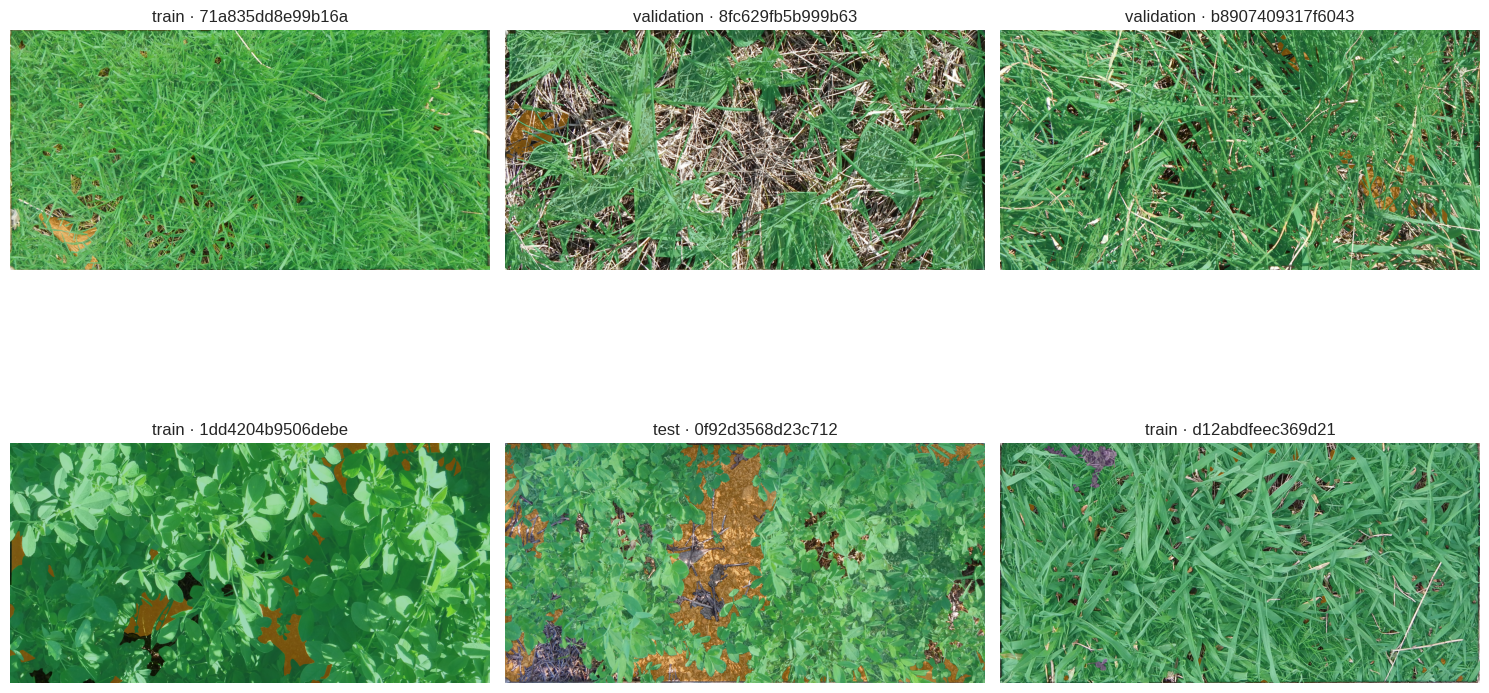

In [12]:
# 12. EDA: dominios, splits, resoluciones, píxeles por clase, ignore y overlays.
CLASS_NAMES = ["césped", "suelo expuesto", "otra vegetación"]
CLASS_COLORS = np.array([[39, 174, 96], [243, 156, 18], [142, 68, 173]], dtype=np.uint8)

def mask_overlay(image: np.ndarray, mask: np.ndarray, alpha: float = 0.45) -> np.ndarray:
    color = np.zeros_like(image)
    valid = mask != 255
    color[valid] = CLASS_COLORS[mask[valid]]
    out = image.copy()
    out[valid] = ((1 - alpha) * image[valid] + alpha * color[valid]).astype(np.uint8)
    return out

def compute_eda(df: pd.DataFrame, name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    resolution_rows, counts = [], np.zeros(4, dtype=np.int64)
    for _, row in df.iterrows():
        image, mask = load_aligned_pair(row.image_path, row.mask_path, row.domain)
        h, w = image.shape[:2]
        resolution_rows.append({"id": row.source_image_id, "width": w, "height": h, "domain": row.domain, "split": row.split})
        vals, n = np.unique(mask, return_counts=True)
        for v, c in zip(vals, n):
            counts[{0: 0, 1: 1, 2: 2, 255: 3}[int(v)]] += int(c)
    res = pd.DataFrame(resolution_rows)
    pix = pd.DataFrame({"clase": CLASS_NAMES + ["ignore"], "pixeles": counts})
    pix["proporcion"] = pix["pixeles"] / max(pix["pixeles"].sum(), 1)
    res.to_csv(OUTPUT_DIR / f"eda_resolutions_{name}.csv", index=False)
    pix.to_csv(OUTPUT_DIR / f"eda_pixels_{name}.csv", index=False)
    return res, pix

public_resolutions, public_pixels = compute_eda(public_manifest, "public")
display(public_manifest.groupby(["domain", "split"]).size().rename("n").reset_index())
display(public_resolutions.groupby("split")[["width", "height"]].describe())
display(public_pixels)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (_, row) in zip(axes.flat, public_manifest.sample(min(6, len(public_manifest)), random_state=CFG.seed).iterrows()):
    image, mask = load_aligned_pair(row.image_path, row.mask_path, row.domain)
    ax.imshow(mask_overlay(image, mask)); ax.set_title(f"{row.split} · {row.source_image_id}"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_overlays.png", dpi=160, bbox_inches="tight"); plt.show()


## 4. Baseline E0: vegetación/suelo

E0 es deliberadamente binario. Combina saturación HSV, Excess Green y morfología. Los umbrales se seleccionan **sólo con validation** y luego se reportan en test. Césped y otra vegetación se colapsan a “vegetación”; no se atribuyen métricas multiclase a este baseline.


Mejor configuración E0 (elegida sólo en validation): {'threshold': 0.55, 'kernel': 7.0, 'iou_soil': 0.13316951363485188, 'f1_soil': 0.19403308516266596}
E0 test público: {'iou_soil': 0.1978937476738514, 'precision_soil': 0.2822852792459909, 'recall_soil': 0.4103508595526328, 'f1_soil': 0.259427801416909, 'mae_soil_pct': 8.461615282497705, 'tn': 15838123, 'fp': 1635014, 'fn': 232284, 'tp': 2095868}


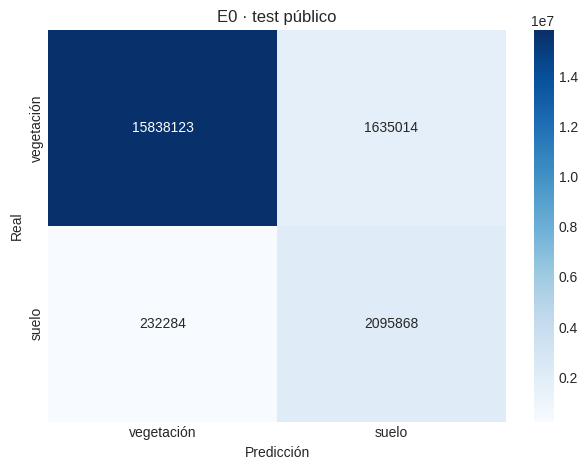

In [13]:
# 13. Baseline binario, ajuste en validation y evaluación en test.
def resize_for_baseline(image: np.ndarray, mask: np.ndarray, max_side: int = 1024) -> tuple[np.ndarray, np.ndarray]:
    h, w = image.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale == 1.0:
        return image, mask
    size = (round(w * scale), round(h * scale))
    return cv2.resize(image, size, interpolation=cv2.INTER_AREA), cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST)

def baseline_soil_mask(image_rgb: np.ndarray, threshold: float, kernel: int) -> np.ndarray:
    rgb = image_rgb.astype(np.float32) / 255.0
    exg = 2 * rgb[:, :, 1] - rgb[:, :, 0] - rgb[:, :, 2]
    exg = np.clip((exg + 1) / 2, 0, 1)
    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    saturation = hsv[:, :, 1].astype(np.float32) / 255.0
    value = hsv[:, :, 2]
    vegetation_score = 0.65 * exg + 0.35 * saturation
    soil = ((vegetation_score < threshold) & (value > 18) & (value < 250)).astype(np.uint8)
    k = np.ones((kernel, kernel), np.uint8)
    soil = cv2.morphologyEx(soil, cv2.MORPH_OPEN, k)
    return cv2.morphologyEx(soil, cv2.MORPH_CLOSE, k)

def binary_soil_metrics(target: np.ndarray, pred: np.ndarray) -> dict[str, float]:
    valid = target != 255
    y = (target[valid] == 1).astype(np.uint8)
    p = pred[valid].astype(np.uint8)
    tp = int(((y == 1) & (p == 1)).sum()); fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum()); tn = int(((y == 0) & (p == 0)).sum())
    precision = tp / max(tp + fp, 1); recall = tp / max(tp + fn, 1)
    iou = tp / max(tp + fp + fn, 1); f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    true_pct = 100 * y.mean() if len(y) else np.nan
    pred_pct = 100 * p.mean() if len(p) else np.nan
    return {"iou_soil": iou, "precision_soil": precision, "recall_soil": recall, "f1_soil": f1,
            "mae_soil_pct": abs(true_pct - pred_pct), "tn": tn, "fp": fp, "fn": fn, "tp": tp}

def evaluate_baseline(frame: pd.DataFrame, threshold: float, kernel: int) -> tuple[dict[str, float], pd.DataFrame]:
    rows = []
    for _, row in frame.iterrows():
        image, mask = load_aligned_pair(row.image_path, row.mask_path, row.domain)
        image, mask = resize_for_baseline(image, mask)
        pred = baseline_soil_mask(image, threshold, kernel)
        rows.append({"id": row.source_image_id, **binary_soil_metrics(mask, pred)})
    detail = pd.DataFrame(rows)
    summary = {k: float(detail[k].mean()) for k in ["iou_soil", "precision_soil", "recall_soil", "f1_soil", "mae_soil_pct"]}
    for key in ["tn", "fp", "fn", "tp"]:
        summary[key] = int(detail[key].sum())
    return summary, detail

validation_frame = public_manifest[public_manifest.split.eq("validation")]
grid_rows = []
for threshold in np.linspace(0.20, 0.55, 8):
    for kernel in [3, 5, 7]:
        summary, _ = evaluate_baseline(validation_frame, float(threshold), kernel)
        grid_rows.append({"threshold": threshold, "kernel": kernel, **summary})
baseline_grid = pd.DataFrame(grid_rows).sort_values(["iou_soil", "f1_soil"], ascending=False)
best_e0 = baseline_grid.iloc[0]
e0_test, e0_detail = evaluate_baseline(
    public_manifest[public_manifest.split.eq("test")], float(best_e0.threshold), int(best_e0.kernel)
)
baseline_grid.to_csv(HISTORY_DIR / "E0_validation_grid.csv", index=False)
e0_detail.to_csv(HISTORY_DIR / "E0_test_per_image.csv", index=False)
print("Mejor configuración E0 (elegida sólo en validation):", best_e0[["threshold", "kernel", "iou_soil", "f1_soil"]].to_dict())
print("E0 test público:", e0_test)
cm_e0 = np.array([[e0_test["tn"], e0_test["fp"]], [e0_test["fn"], e0_test["tp"]]])
sns.heatmap(cm_e0, annot=True, fmt="d", cmap="Blues", xticklabels=["vegetación", "suelo"], yticklabels=["vegetación", "suelo"])
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("E0 · test público")
plt.tight_layout(); plt.savefig(FIG_DIR / "E0_confusion_matrix.png", dpi=160); plt.show()


## 5. U-Net, pérdida, métricas y entrenamiento

La red es U-Net con encoder ResNet-34 y tres canales de *logits*. La pérdida combina 0.5×cross-entropy ponderada y 0.5×Dice multiclase, excluyendo 255. No se aplica softmax antes de cross-entropy. Los pesos se calculan sólo sobre train y se limitan a [0.5, 5.0].


In [14]:
# 14. Modelo, pérdida compuesta y pesos de clase.
def build_model(encoder_weights: Optional[str]) -> nn.Module:
    return smp.Unet(encoder_name="resnet34", encoder_weights=encoder_weights, in_channels=3, classes=3, activation=None)

def compute_class_weights(frame: pd.DataFrame) -> torch.Tensor:
    counts = np.zeros(3, dtype=np.int64)
    for _, row in frame[frame.split.eq("train")].iterrows():
        _, mask = load_aligned_pair(row.image_path, row.mask_path, row.domain)
        for c in range(3):
            counts[c] += int((mask == c).sum())
    if (counts == 0).any():
        print("Advertencia: clase ausente en train; su peso se limita sin inventar píxeles.", counts)
    frequencies = counts / max(counts.sum(), 1)
    weights = 1.0 / np.sqrt(np.maximum(frequencies, 1e-12))
    weights = weights / weights.mean()
    weights = np.clip(weights, 0.5, 5.0)
    return torch.tensor(weights, dtype=torch.float32)

class CEDiceLoss(nn.Module):
    def __init__(self, class_weights: torch.Tensor):
        super().__init__()
        self.register_buffer("class_weights", class_weights)
    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        valid = target != 255
        if not bool(valid.any()):
            return logits.sum() * 0.0
        ce = F.cross_entropy(logits, target, weight=self.class_weights, ignore_index=255)
        probs = torch.softmax(logits, dim=1)
        safe_target = target.clone(); safe_target[~valid] = 0
        one_hot = F.one_hot(safe_target, num_classes=3).permute(0, 3, 1, 2).float()
        valid4 = valid.unsqueeze(1)
        probs = probs * valid4; one_hot = one_hot * valid4
        intersection = (probs * one_hot).sum((0, 2, 3))
        denominator = (probs + one_hot).sum((0, 2, 3))
        present = one_hot.sum((0, 2, 3)) > 0
        dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
        dice_loss = 1 - dice[present].mean() if bool(present.any()) else logits.sum() * 0.0
        return 0.5 * ce + 0.5 * dice_loss

class ConfusionAccumulator:
    def __init__(self):
        self.cm = np.zeros((3, 3), dtype=np.int64)
        self.per_image = []
    def update(self, logits: torch.Tensor, target: torch.Tensor, ids: Iterable[str]) -> None:
        pred = logits.argmax(1).detach().cpu().numpy()
        target_np = target.detach().cpu().numpy()
        for p, y, image_id in zip(pred, target_np, ids):
            valid = y != 255
            if not valid.any():
                continue
            self.cm += confusion_matrix(y[valid], p[valid], labels=[0, 1, 2])
            row = {"id": image_id}
            dices = []
            for c in range(3):
                inter = ((p == c) & (y == c) & valid).sum()
                den = ((p == c) & valid).sum() + ((y == c) & valid).sum()
                d = (2 * inter / den) if den else np.nan
                row[f"dice_{c}"] = d; dices.append(d)
                row[f"true_pct_{c}"] = 100 * ((y == c) & valid).sum() / valid.sum()
                row[f"pred_pct_{c}"] = 100 * ((p == c) & valid).sum() / valid.sum()
            row["macro_dice_image"] = float(np.nanmean(dices))
            self.per_image.append(row)
    def summary(self) -> dict[str, Any]:
        tp = np.diag(self.cm).astype(float)
        fp = self.cm.sum(0) - tp; fn = self.cm.sum(1) - tp
        iou = tp / np.maximum(tp + fp + fn, 1)
        dice = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
        precision_soil = tp[1] / max(tp[1] + fp[1], 1)
        recall_soil = tp[1] / max(tp[1] + fn[1], 1)
        f1_soil = 2 * precision_soil * recall_soil / max(precision_soil + recall_soil, 1e-12)
        detail = pd.DataFrame(self.per_image)
        result = {f"iou_{c}": float(iou[c]) for c in range(3)}
        result.update({f"dice_{c}": float(dice[c]) for c in range(3)})
        result.update({"mean_iou": float(iou.mean()), "macro_dice": float(dice.mean()),
                       "precision_soil": float(precision_soil), "recall_soil": float(recall_soil), "f1_soil": float(f1_soil)})
        for c in range(3):
            result[f"mae_pct_{c}"] = float((detail[f"true_pct_{c}"] - detail[f"pred_pct_{c}"]).abs().mean()) if len(detail) else np.nan
        return result


In [15]:
# 15. Ciclos de entrenamiento/evaluación, checkpoints y early stopping.
def set_encoder_trainable(model: nn.Module, trainable: bool) -> None:
    for p in model.encoder.parameters():
        p.requires_grad = trainable

def freeze_encoder_batchnorm(model: nn.Module) -> None:
    for module in model.encoder.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()

def run_epoch(model, loader, criterion, optimizer=None, freeze_bn=False) -> tuple[float, dict[str, Any], ConfusionAccumulator]:
    training = optimizer is not None
    model.train(training)
    if training and freeze_bn:
        freeze_encoder_batchnorm(model)
    meter = ConfusionAccumulator(); loss_sum = 0.0; seen = 0
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    context = torch.enable_grad if training else torch.no_grad
    with context():
        for batch in loader:
            x = batch["image"].to(DEVICE, non_blocking=True)
            y = batch["mask"].to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=AMP_ENABLED):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update()
            loss_sum += float(loss.detach()) * x.size(0); seen += x.size(0)
            meter.update(logits, y, batch["id"])
    return loss_sum / max(seen, 1), meter.summary(), meter

def save_checkpoint(path: Path, model: nn.Module, optimizer, epoch: int, best_miou: float, metadata: dict[str, Any]) -> None:
    torch.save({"model_state": model.state_dict(), "optimizer_state": optimizer.state_dict() if optimizer else None,
                "epoch": epoch, "best_miou": best_miou, "metadata": metadata}, path)

def load_model_from_checkpoint(path: str | Path, device: torch.device = DEVICE) -> nn.Module:
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model = build_model(encoder_weights=None)
    model.load_state_dict(checkpoint["model_state"])
    model.to(device).eval()
    return model

def train_stage(name: str, model: nn.Module, loaders: dict[str, DataLoader], class_weights: torch.Tensor,
                epochs: int, lr: float, patience: int, output_group: str,
                encoder_trainable: bool, freeze_bn: bool, use_scheduler: bool,
                resume_path: Optional[Path] = None) -> dict[str, Any]:
    model = model.to(DEVICE)
    if resume_path is not None:
        model.load_state_dict(torch.load(resume_path, map_location=DEVICE, weights_only=False)["model_state"])
    set_encoder_trainable(model, encoder_trainable)
    criterion = CEDiceLoss(class_weights.to(DEVICE))
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2) if use_scheduler else None
    group_dir = CKPT_DIR / output_group; group_dir.mkdir(parents=True, exist_ok=True)
    best_path = group_dir / f"{name}_best.pt"
    history, best, stale = [], -np.inf, 0
    for epoch in range(1, epochs + 1):
        train_loss, train_metrics, _ = run_epoch(model, loaders["train"], criterion, optimizer, freeze_bn)
        val_loss, val_metrics, _ = run_epoch(model, loaders["validation"], criterion)
        if scheduler:
            scheduler.step(val_metrics["mean_iou"])
        row = {"experiment": name, "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
               "lr": optimizer.param_groups[0]["lr"],
               **{f"train_{k}": v for k, v in train_metrics.items()},
               **{f"val_{k}": v for k, v in val_metrics.items()}}
        history.append(row)
        print(f"{name} época {epoch:02d} | loss {train_loss:.4f}/{val_loss:.4f} | val mIoU {val_metrics['mean_iou']:.4f}")
        if val_metrics["mean_iou"] > best + 1e-6:
            best = val_metrics["mean_iou"]; stale = 0
            save_checkpoint(best_path, model, optimizer, epoch, best, {"name": name, "output_group": output_group})
        else:
            stale += 1
            if stale >= patience:
                print(f"Early stopping en {name}, época {epoch}."); break
    hist = pd.DataFrame(history)
    hist_path = HISTORY_DIR / f"{output_group}_{name}.csv"; hist.to_csv(hist_path, index=False)
    best_model = load_model_from_checkpoint(best_path)
    criterion = CEDiceLoss(class_weights.to(DEVICE))
    test_loss, test_metrics, test_meter = run_epoch(best_model, loaders["test"], criterion)
    detail = pd.DataFrame(test_meter.per_image)
    detail.to_csv(HISTORY_DIR / f"{output_group}_{name}_test_per_image.csv", index=False)
    return {"name": name, "group": output_group, "best_checkpoint": str(best_path),
            "best_val_miou": float(best), "test_loss": test_loss, "test_metrics": test_metrics,
            "history": hist, "test_detail": detail, "test_cm": test_meter.cm}


In [16]:
# 16. E1–E3: primero smoke test (máximo dos épocas por etapa), luego corrida completa acotada.
def run_public_suite(frame: pd.DataFrame, fast: bool, batch_size: int) -> dict[str, Any]:
    mode = "smoke" if fast else "full"
    data = subset_for_mode(frame, fast)
    loaders = make_loaders(data, batch_size=batch_size)
    weights = compute_class_weights(data)
    print(f"Modo {mode} | batch={batch_size} | pesos={weights.tolist()} | imágenes={len(data)}")
    ep_e1, ep_e2, ep_e3 = (2, 2, 2) if fast else (12, 3, 15)
    p_e1, p_e2, p_e3 = (2, 2, 2) if fast else (3, 3, 4)
    e1 = train_stage("E1", build_model(None), loaders, weights, ep_e1, 1e-3, p_e1, mode,
                     encoder_trainable=True, freeze_bn=False, use_scheduler=False)
    e2 = train_stage("E2", build_model("imagenet"), loaders, weights, ep_e2, 1e-3, p_e2, mode,
                     encoder_trainable=False, freeze_bn=True, use_scheduler=False)
    e3 = train_stage("E3", build_model(None), loaders, weights, ep_e3, 1e-4, p_e3, mode,
                     encoder_trainable=True, freeze_bn=False, use_scheduler=True,
                     resume_path=Path(e2["best_checkpoint"]))
    return {"mode": mode, "data": data, "loaders": loaders, "weights": weights, "E1": e1, "E2": e2, "E3": e3}

def run_with_oom_fallback(frame: pd.DataFrame, fast: bool) -> dict[str, Any]:
    try:
        return run_public_suite(frame, fast, CFG.batch_size)
    except torch.cuda.OutOfMemoryError:
        if DEVICE.type != "cuda" or CFG.batch_size == 1:
            raise
        print("Memoria GPU insuficiente con batch 2; se limpia memoria y se repite con batch 1.")
        gc.collect(); torch.cuda.empty_cache()
        return run_public_suite(frame, fast, 1)

experiment_runs: dict[str, Any] = {}
if RUN_SMOKE:
    experiment_runs["smoke"] = run_with_oom_fallback(public_manifest, fast=True)
    print("Smoke test completado; checkpoints separados en checkpoints/smoke/.")
if RUN_FULL:
    experiment_runs["full"] = run_with_oom_fallback(public_manifest, fast=False)
    print("Corrida completa acotada completada; checkpoints separados en checkpoints/full/.")


/tmp/ipykernel_2524/626050059.py:77: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), CFG.smoke_per_split), random_state=CFG.seed))


Modo smoke | batch=2 | pesos=[0.5, 1.9180949926376343, 0.741685152053833] | imágenes=18
E1 época 01 | loss 0.9740/125.6942 | val mIoU 0.0114
E1 época 02 | loss 0.8747/43.5221 | val mIoU 0.0322


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

E2 época 01 | loss 0.9280/0.5305 | val mIoU 0.3242
E2 época 02 | loss 0.7867/0.5295 | val mIoU 0.3115
E3 época 01 | loss 0.8028/0.7408 | val mIoU 0.2467
E3 época 02 | loss 0.7548/0.8294 | val mIoU 0.2021
Smoke test completado; checkpoints separados en checkpoints/smoke/.
Modo full | batch=2 | pesos=[0.5, 1.5480313301086426, 0.9826701879501343] | imágenes=300
E1 época 01 | loss 0.7437/0.7038 | val mIoU 0.3552
E1 época 02 | loss 0.6986/0.5833 | val mIoU 0.4134
E1 época 03 | loss 0.6994/0.6480 | val mIoU 0.3648
E1 época 04 | loss 0.7040/0.6050 | val mIoU 0.4411
E1 época 05 | loss 0.6770/0.5895 | val mIoU 0.4339
E1 época 06 | loss 0.6762/0.6124 | val mIoU 0.3606
E1 época 07 | loss 0.6749/0.5466 | val mIoU 0.4020
Early stopping en E1, época 7.
E2 época 01 | loss 0.6885/0.5096 | val mIoU 0.4340
E2 época 02 | loss 0.6063/0.4537 | val mIoU 0.6200
E2 época 03 | loss 0.5774/0.4539 | val mIoU 0.6361
E3 época 01 | loss 0.5568/0.4693 | val mIoU 0.5432
E3 época 02 | loss 0.5807/0.4829 | val mIoU 0.5

,mode,experiment,best_val_miou,iou_soil,precision_soil,recall_soil,f1_soil,mae_soil_pct,tn,fp,...,iou_1,iou_2,dice_0,dice_1,dice_2,mean_iou,macro_dice,mae_pct_0,mae_pct_1,mae_pct_2
0,full,E0,NaN,0.197894,0.282285,0.410351,0.259428,8.461615,15838123.0,1635014.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,smoke,E1,0.032241,NaN,0.008507,0.825632,0.016841,NaN,NaN,NaN,...,0.008492,0.001450,0.169346,0.016841,0.002895,0.034149,0.063027,83.782620,89.303224,5.736854
2,smoke,E2,0.324234,NaN,0.013185,0.004353,0.006545,NaN,NaN,NaN,...,0.003283,0.019227,0.954848,0.006545,0.037729,0.312036,0.333041,5.886731,0.973308,5.423699
3,smoke,E3,0.246721,NaN,0.016848,0.048468,0.025004,NaN,NaN,NaN,...,0.012660,0.096941,0.862087,0.025004,0.176747,0.289068,0.354613,13.574052,1.737716,11.836336
4,full,E1,0.441060,NaN,0.765023,0.858429,0.809039,NaN,NaN,NaN,...,0.679316,0.033273,0.905049,0.809039,0.064404,0.513052,0.592830,13.967100,4.142378,11.054286
5,full,E2,0.636110,NaN,0.758141,0.923449,0.832669,NaN,NaN,NaN,...,0.713311,0.454037,0.916808,0.832669,0.624519,0.671247,0.791332,9.986764,3.811062,6.897225
6,full,E3,0.682121,NaN,0.797519,0.923057,0.855708,NaN,NaN,NaN,...,0.747806,0.469894,0.933441,0.855708,0.639357,0.697629,0.809502,8.067768,3.701593,5.271899


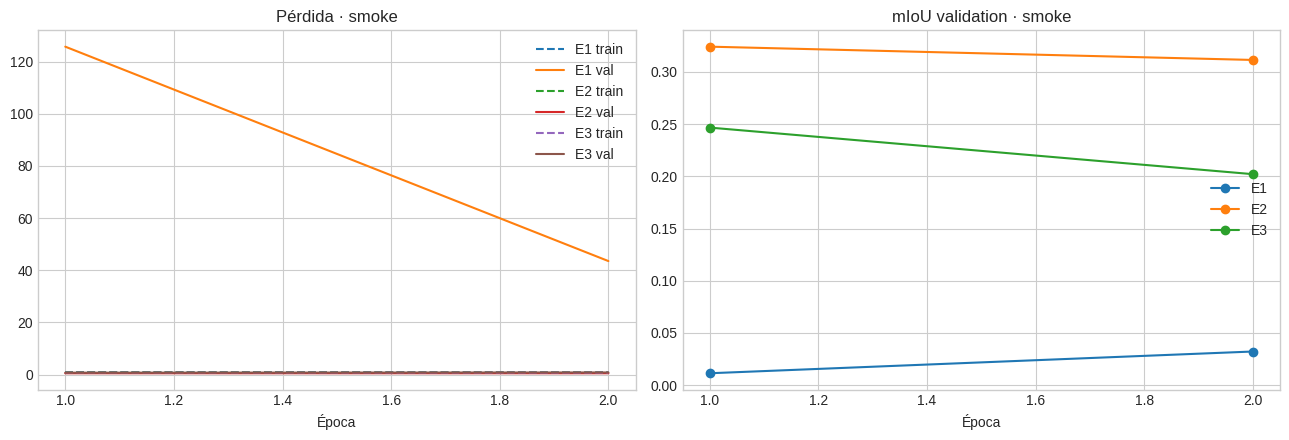

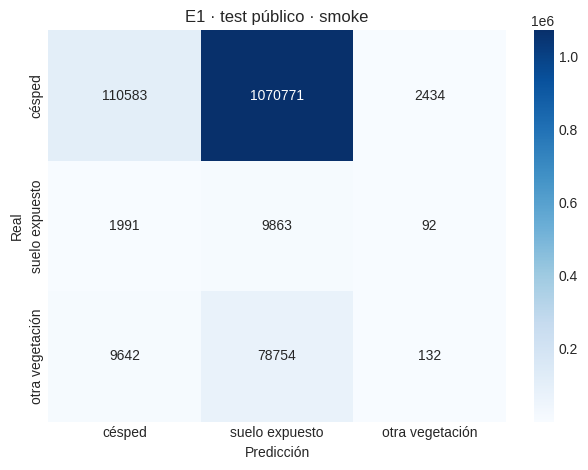

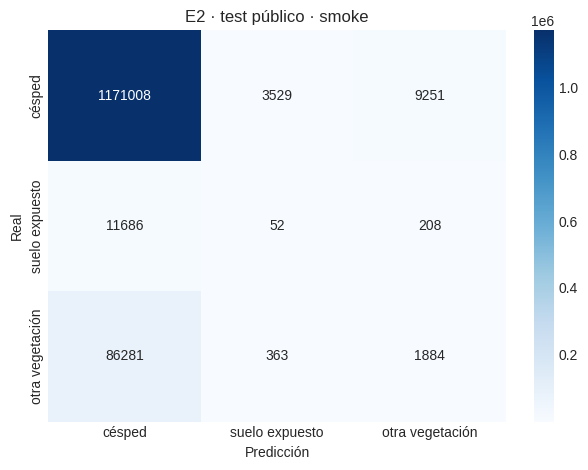

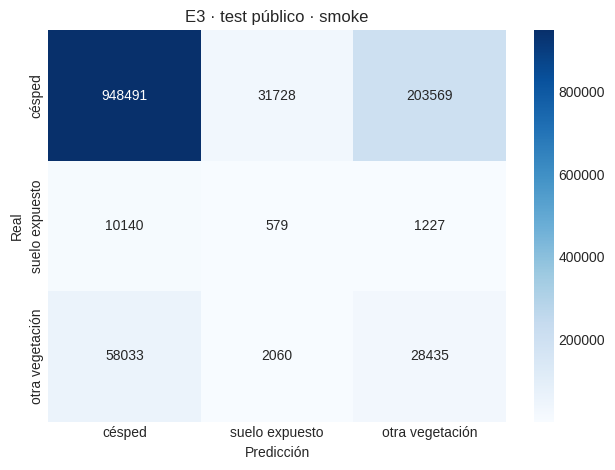

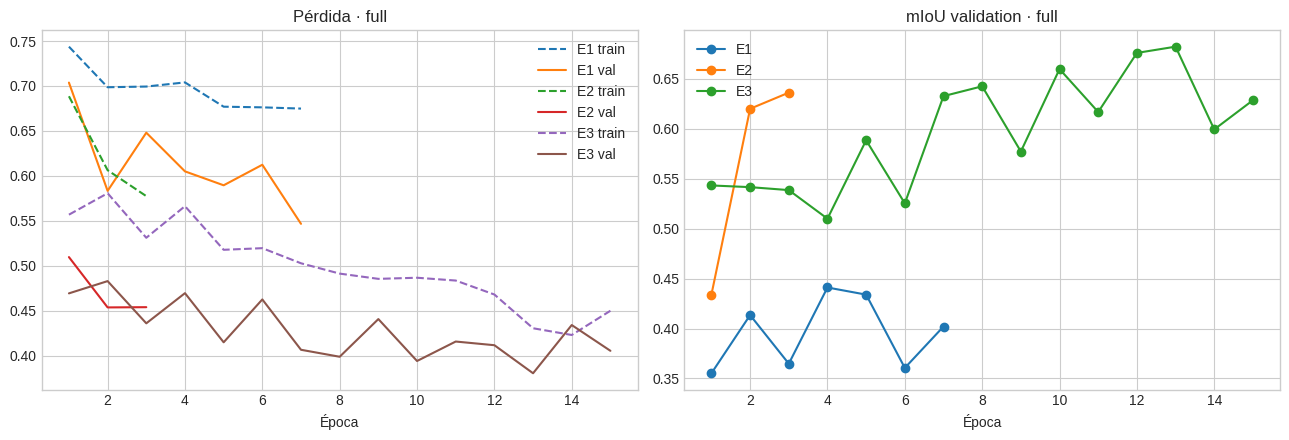

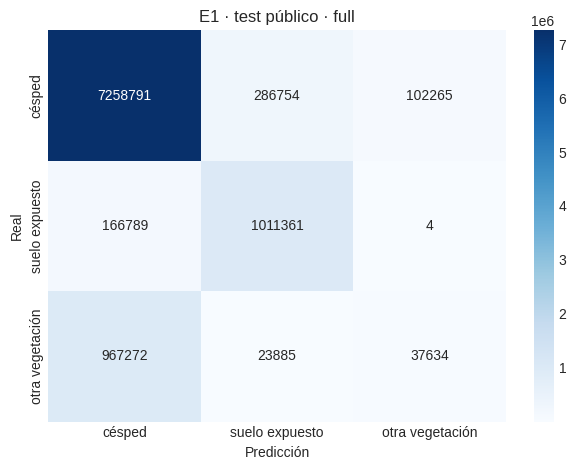

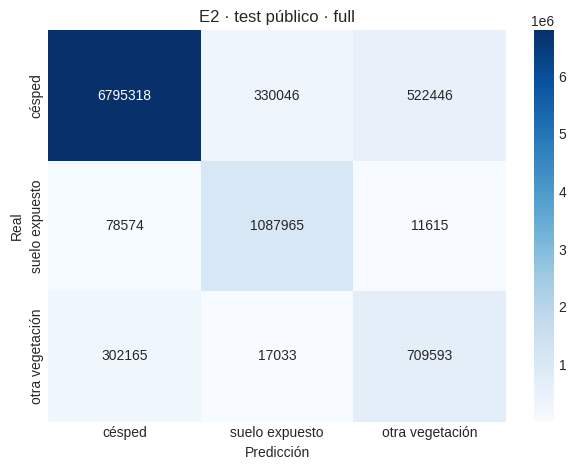

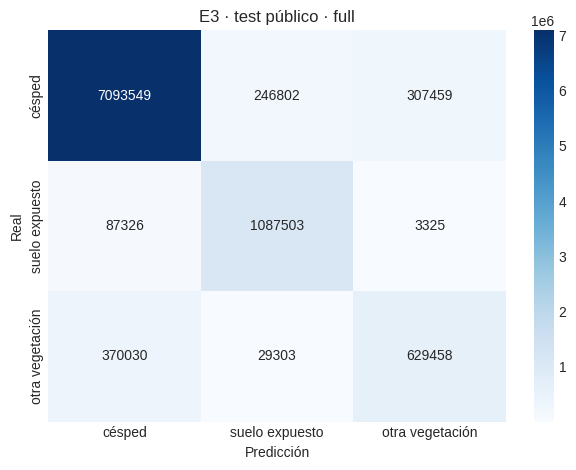

In [17]:
# 17. Tablas y gráficos reales de E1–E3.
def summarize_runs(runs: dict[str, Any]) -> pd.DataFrame:
    rows = [{"mode": "full", "experiment": "E0", "best_val_miou": np.nan, **e0_test}]
    for mode, suite in runs.items():
        for name in ["E1", "E2", "E3"]:
            result = suite[name]
            rows.append({"mode": mode, "experiment": name, "best_val_miou": result["best_val_miou"], **result["test_metrics"]})
    return pd.DataFrame(rows)

results_table = summarize_runs(experiment_runs)
results_table.to_csv(OUTPUT_DIR / "results_summary.csv", index=False)
display(results_table)

for mode, suite in experiment_runs.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for name in ["E1", "E2", "E3"]:
        hist = suite[name]["history"]
        axes[0].plot(hist.epoch, hist.train_loss, "--", label=f"{name} train")
        axes[0].plot(hist.epoch, hist.val_loss, label=f"{name} val")
        axes[1].plot(hist.epoch, hist.val_mean_iou, marker="o", label=name)
    axes[0].set_title(f"Pérdida · {mode}"); axes[1].set_title(f"mIoU validation · {mode}")
    for ax in axes: ax.set_xlabel("Época"); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / f"training_curves_{mode}.png", dpi=160); plt.show()

    for name in ["E1", "E2", "E3"]:
        cm = suite[name]["test_cm"]
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        plt.title(f"{name} · test público · {mode}"); plt.xlabel("Predicción"); plt.ylabel("Real")
        plt.tight_layout(); plt.savefig(FIG_DIR / f"{mode}_{name}_confusion_matrix.png", dpi=160); plt.show()


## 6. Inferencia sobre imágenes completas

`predict_lawn` usa ventanas solapadas de 512×512 y promedia logits. Devuelve máscara, overlay, tres porcentajes y un mapa binario de suelo expuesto. Los porcentajes se calculan sobre la misma región válida y suman aproximadamente 100%.


In [18]:
# 18. Inferencia tiled, visualizaciones y mejores/peores ejemplos.
def normalize_tensor(image: np.ndarray) -> torch.Tensor:
    x = image.astype(np.float32) / 255.0
    x = (x - np.array(IMAGENET_MEAN, np.float32)) / np.array(IMAGENET_STD, np.float32)
    return torch.from_numpy(x.transpose(2, 0, 1)).float()

@torch.no_grad()
def predict_array_tiled(image: np.ndarray, model: nn.Module, device: torch.device, tile: int = 512, overlap: int = 64) -> np.ndarray:
    h, w = image.shape[:2]
    pad_h, pad_w = max(0, tile - h), max(0, tile - w)
    padded = cv2.copyMakeBorder(image, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT_101)
    ph, pw = padded.shape[:2]; stride = tile - overlap
    ys = list(range(0, max(ph - tile, 0) + 1, stride)); xs = list(range(0, max(pw - tile, 0) + 1, stride))
    if ys[-1] != ph - tile: ys.append(ph - tile)
    if xs[-1] != pw - tile: xs.append(pw - tile)
    logits_sum = np.zeros((3, ph, pw), dtype=np.float32); weight = np.zeros((ph, pw), dtype=np.float32)
    model.eval()
    for y in ys:
        for x in xs:
            tensor = normalize_tensor(padded[y:y+tile, x:x+tile]).unsqueeze(0).to(device)
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                logits = model(tensor)[0].float().cpu().numpy()
            logits_sum[:, y:y+tile, x:x+tile] += logits; weight[y:y+tile, x:x+tile] += 1
    return (logits_sum / np.maximum(weight, 1)[None]).argmax(0)[:h, :w].astype(np.uint8)

def predict_lawn(image_path: str | Path, model: nn.Module, device: torch.device = DEVICE) -> dict[str, Any]:
    with Image.open(image_path) as im:
        image = np.array(ImageOps.exif_transpose(im).convert("RGB"))
    mask = predict_array_tiled(image, model, device)
    percentages = [100 * (mask == c).mean() for c in range(3)]
    result = {
        "mask": mask, "overlay": mask_overlay(image, mask),
        "grass_percentage": float(percentages[0]),
        "soil_percentage": float(percentages[1]),
        "other_vegetation_percentage": float(percentages[2]),
        "exposed_soil_map": (mask == 1).astype(np.uint8),
    }
    assert abs(sum(percentages) - 100.0) < 1e-6
    return result

preferred_mode = "full" if "full" in experiment_runs else "smoke"
best_transfer_name = max(["E2", "E3"], key=lambda n: experiment_runs[preferred_mode][n]["best_val_miou"])
best_public_checkpoint = Path(experiment_runs[preferred_mode][best_transfer_name]["best_checkpoint"])
best_public_model = load_model_from_checkpoint(best_public_checkpoint)
print(f"Checkpoint elegido por validation pública: {preferred_mode}/{best_transfer_name} -> {best_public_checkpoint}")

def save_qualitative_examples(frame: pd.DataFrame, model: nn.Module, tag: str, limit: int = 8) -> pd.DataFrame:
    rows = []
    for _, row in frame.iterrows():
        image, target = load_aligned_pair(row.image_path, row.mask_path, row.domain)
        pred = predict_array_tiled(image, model, DEVICE)
        valid = target != 255
        dices = []
        for c in range(3):
            inter = ((pred == c) & (target == c) & valid).sum()
            den = ((pred == c) & valid).sum() + ((target == c) & valid).sum()
            dices.append(2 * inter / den if den else np.nan)
        rows.append({"id": row.source_image_id, "score": float(np.nanmean(dices)), "image": image, "target": target, "pred": pred})
    ranked = sorted(rows, key=lambda r: r["score"])
    chosen = ranked[:limit//2] + ranked[-limit//2:]
    fig, axes = plt.subplots(len(chosen), 3, figsize=(13, 4 * len(chosen)))
    if len(chosen) == 1: axes = np.array([axes])
    for axrow, item in zip(axes, chosen):
        axrow[0].imshow(item["image"]); axrow[0].set_title(f"RGB · Dice {item['score']:.3f}")
        axrow[1].imshow(mask_overlay(item["image"], item["target"])); axrow[1].set_title("Real")
        axrow[2].imshow(mask_overlay(item["image"], item["pred"])); axrow[2].set_title("Predicción")
        for ax in axrow: ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"best_worst_{tag}.png", dpi=140, bbox_inches="tight"); plt.show()
    return pd.DataFrame([{"id": r["id"], "macro_dice_image": r["score"]} for r in ranked])

qualitative_ranking = save_qualitative_examples(public_manifest[public_manifest.split.eq("test")], best_public_model, preferred_mode)
qualitative_ranking.to_csv(OUTPUT_DIR / f"qualitative_ranking_{preferred_mode}.csv", index=False)


Output hidden; open in https://colab.research.google.com to view.

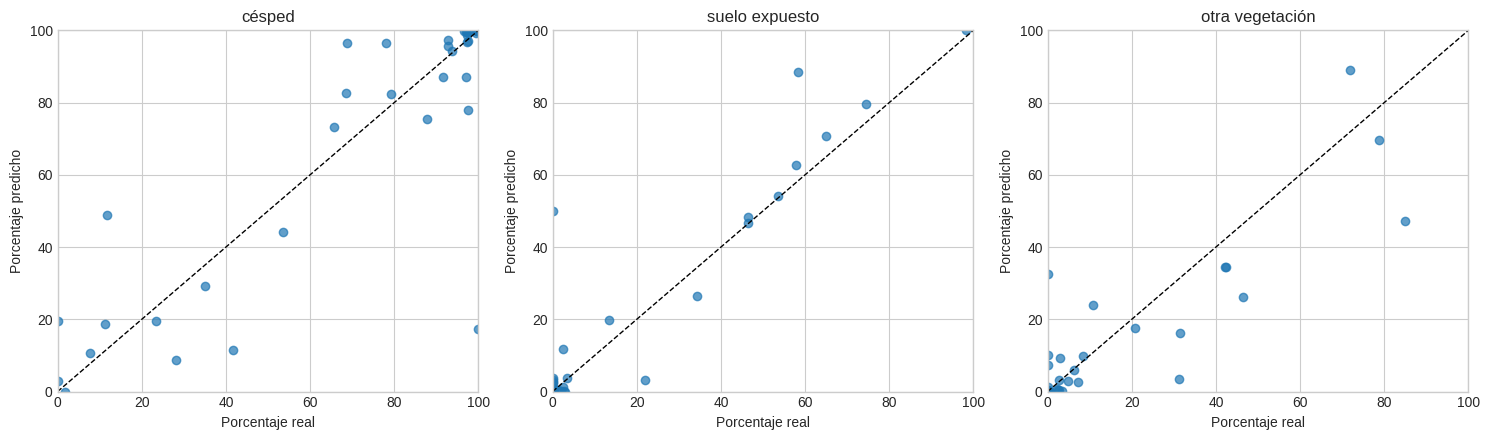

In [19]:
# 19. Dispersión de porcentajes real/predicho con la misma región válida.
detail = experiment_runs[preferred_mode][best_transfer_name]["test_detail"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for c, ax in enumerate(axes):
    ax.scatter(detail[f"true_pct_{c}"], detail[f"pred_pct_{c}"], alpha=0.7)
    ax.plot([0, 100], [0, 100], "k--", lw=1)
    ax.set(xlabel="Porcentaje real", ylabel="Porcentaje predicho", title=CLASS_NAMES[c], xlim=(0, 100), ylim=(0, 100))
plt.tight_layout(); plt.savefig(FIG_DIR / f"percentage_scatter_{preferred_mode}.png", dpi=160); plt.show()


## 7. Cambio de dominio: E4 y E5

- **E4:** mejor checkpoint entre E2/E3 por validation pública, evaluado directamente en test local.
- **E5:** adaptación con train local, selección en validation local y evaluación en test local.

Si no existe el ZIP local, ambos quedan registrados como “no ejecutado: sin datos locales”.


In [21]:
# 20. E4/E5 locales opcionales.
local_results: dict[str, Any] = {}
if local_manifest is None:
    local_results = {"E4": "no ejecutado: sin datos locales", "E5": "no ejecutado: sin datos locales"}
    print(local_results)
else:
    annotated_local = local_manifest[local_manifest.split.isin(["train", "validation", "test"])].copy()
    local_loaders = make_loaders(annotated_local, batch_size=1)
    local_weights = compute_class_weights(annotated_local)
    criterion = CEDiceLoss(local_weights.to(DEVICE))
    e4_model = load_model_from_checkpoint(best_public_checkpoint)
    e4_loss, e4_metrics, e4_meter = run_epoch(e4_model, local_loaders["test"], criterion)
    pd.DataFrame(e4_meter.per_image).to_csv(HISTORY_DIR / "E4_local_test_per_image.csv", index=False)
    local_results["E4"] = {"test_loss": e4_loss, **e4_metrics}
    e5 = train_stage("E5", build_model(None), local_loaders, local_weights,
                     epochs=2 if FAST_MODE else 10, lr=1e-5, patience=2 if FAST_MODE else 3,
                     output_group="local", encoder_trainable=True, freeze_bn=False,
                     use_scheduler=True, resume_path=best_public_checkpoint)
    local_results["E5"] = {"best_val_miou": e5["best_val_miou"], "test_loss": e5["test_loss"], **e5["test_metrics"]}
    print(json.dumps(local_results, indent=2))
(OUTPUT_DIR / "local_results.json").write_text(json.dumps(local_results, indent=2), encoding="utf-8")


{'E4': 'no ejecutado: sin datos locales', 'E5': 'no ejecutado: sin datos locales'}


88

## 8. Pruebas automáticas

Estas verificaciones cubren alineación, valores de máscara, leakage, porcentajes, forma de logits, pérdida con clases ausentes/ignore, checkpoint reconstruido y tamaños menores/mayores a 512. Las imágenes aleatorias se usan sólo como pruebas unitarias de forma; nunca sustituyen datos de entrenamiento o métricas.


In [22]:
# 21. Assertions solicitadas.
def run_assertions() -> None:
    assert_no_leakage(public_manifest)
    for _, row in public_manifest.sample(min(10, len(public_manifest)), random_state=CFG.seed).iterrows():
        image, mask = load_aligned_pair(row.image_path, row.mask_path, row.domain)
        assert image.shape[:2] == mask.shape[:2]
        assert set(np.unique(mask)).issubset({0, 1, 2, 255})
    model = load_model_from_checkpoint(best_public_checkpoint)
    x = torch.zeros(1, 3, 512, 512, device=DEVICE)
    with torch.no_grad(): logits = model(x)
    assert logits.shape == (1, 3, 512, 512)
    criterion = CEDiceLoss(torch.ones(3, device=DEVICE))
    all_ignore = torch.full((1, 512, 512), 255, dtype=torch.long, device=DEVICE)
    assert torch.isfinite(criterion(logits, all_ignore))
    absent_classes = torch.zeros((1, 512, 512), dtype=torch.long, device=DEVICE)
    assert torch.isfinite(criterion(logits, absent_classes))
    # Guardado/carga y reconstrucción desde un objeto nuevo.
    clean_model = build_model(None).to(DEVICE)
    state = torch.load(best_public_checkpoint, map_location=DEVICE, weights_only=False)
    clean_model.load_state_dict(state["model_state"]); clean_model.eval()
    with torch.no_grad(): clean_logits = clean_model(x)
    assert clean_logits.shape == logits.shape
    # Tamaños menores y mayores a 512 para la inferencia tiled.
    for shape in [(320, 410), (620, 790)]:
        test_image = np.zeros((*shape, 3), dtype=np.uint8)
        pred = predict_array_tiled(test_image, clean_model, DEVICE)
        assert pred.shape == shape and set(np.unique(pred)).issubset({0, 1, 2})
        percentages = [100 * (pred == c).mean() for c in range(3)]
        assert abs(sum(percentages) - 100) < 1e-6
    print("Todas las assertions pasaron correctamente.")

run_assertions()


Todas las assertions pasaron correctamente.


## 9. Predicción de una fotografía nueva (a Terminar)

Esta es la única celda que usa subida manual. Los porcentajes describen la composición de píxeles de la imagen, y el suelo se presenta como **sectores candidatos a revisión**.


In [ ]:
# 23. Única subida manual permitida: demostración final.
from google.colab import files

uploaded = files.upload()
if not uploaded:
    print("No se seleccionó ninguna imagen.")
else:
    uploaded_name = next(iter(uploaded))
    uploaded_path = ROOT / Path(uploaded_name).name
    uploaded_path.write_bytes(uploaded[uploaded_name])
    demo = predict_lawn(uploaded_path, best_public_model, DEVICE)
    print(f"Césped: {demo['grass_percentage']:.2f}%")
    print(f"Suelo expuesto (sectores candidatos a revisión): {demo['soil_percentage']:.2f}%")
    print(f"Otra vegetación: {demo['other_vegetation_percentage']:.2f}%")
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    original = np.array(ImageOps.exif_transpose(Image.open(uploaded_path)).convert("RGB"))
    axes[0].imshow(original); axes[0].set_title("Imagen")
    axes[1].imshow(demo["overlay"]); axes[1].set_title("Segmentación")
    axes[2].imshow(demo["exposed_soil_map"], cmap="Oranges"); axes[2].set_title("Sectores candidatos a revisión")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()
